# Train V2 trên VS Code · NVIDIA 4 GB

Chọn kernel Python 3.11 của project. Lần đầu cần Internet để tải trọng số. VideoMAE chạy trên GPU, bộ tìm khớp người chạy trên CPU và lưu cache trên đĩa. Mặc định chỉ fine-tune block cuối của VideoMAE cùng các đầu phân loại để giảm bộ nhớ.

Mỗi dòng events.csv mô tả **một sự kiện**. Xem clip trước và sau rồi điền vùng thời gian [start_s, end_s], thời điểm tương tác event_s và cửa sổ ngắn nhất còn đủ bằng chứng min_window_s. Với cú đánh chọn thời điểm ra đòn hoặc chạm. Với vung tay hụt chọn lúc tay đi gần người kia nhất. Quy ước contact là **tiếp xúc của tay người này với người kia tại sự kiện được xét**.

| Ví dụ | scenario | action | contact |
|---|---|---:|---|
| Một cú đánh trúng, có hoặc không có người ngã | fast_strike | 1 | touch |
| Vung tay đi ngang che người, xác nhận không chạm | arm_overlap | 0 | no_touch |
| Vỗ vai hoặc đập tay thân thiện | friendly_touch | 0 | touch |
| Có động tác giống ra đòn, điểm chạm bị che, hành động chưa rõ | occluded | để trống | unclear |
| Động tác tấn công rõ, điểm chạm bị che | occluded | 1 | unclear |

Chỉ dùng nhãn `no_touch` khi quan sát được đủ ngữ cảnh. Nhãn trống bỏ qua loss tương ứng. `unclear` là lớp có giám sát dành cho tiếp xúc bị che. Clip RLVS chỉ có nhãn hành động. Khi bổ sung nhãn cho clip đã có trong RLVS, dùng đúng split của nguồn đó.

Ví dụ một dòng minh họa: `extra/wave.mp4,scene_012,train,arm_overlap,0,no_touch,0,3,1.4,1`. Đặt `min_window_s=1` khi nửa giây quá ngắn để hiểu tình huống. Chọn các **nguồn độc lập** cho train, val, test của từng trường hợp. Ba file KO đã xem thuộc tập chẩn đoán riêng.

In [1]:
import sys, torch, torchvision
print('Kernel', sys.executable)
if not torch.cuda.is_available():
    raise RuntimeError('Chọn kernel .venv có PyTorch CUDA. Xem hướng dẫn trong README.md.')
print('GPU', torch.cuda.get_device_name(), '| PyTorch', torch.__version__, '| CUDA', torch.version.cuda)
print('VRAM còn trống (GiB)', round(torch.cuda.mem_get_info()[0] / 2**30, 2))
print('Thử phép tính CUDA:', (torch.ones(2, device='cuda') * 2).tolist())

Kernel d:\TaiLieu\2026-2027\ATTT\.venv\Scripts\python.exe
GPU NVIDIA GeForce RTX 3050 Laptop GPU | PyTorch 2.6.0+cu124 | CUDA 12.4
VRAM còn trống (GiB) 3.23
Thử phép tính CUDA: [2.0, 2.0]


In [2]:
from pathlib import Path
DATA_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                  if (p/'train_v2/events.csv').is_file() and (p/'dataset').is_dir()), None)
if DATA_ROOT is None:
    raise FileNotFoundError('Mở thư mục ATTT làm workspace và chạy lại kernel.')
LABEL_DIR = DATA_ROOT/'train_v2'
SPLITS = LABEL_DIR/'splits'
RLVS = DATA_ROOT/'dataset'/'Real Life Violence Dataset'
OUT = LABEL_DIR/'runs'/'local_gpu_01'
OLD_BEST = None
EPOCHS, BATCH, ACCUM, SEED = 5, 1, 16, 42
import os
os.environ['TORCH_HOME'] = str(LABEL_DIR/'cache'/'torch')
cached_base = LABEL_DIR/'cache'/'hf'
BASE = str(cached_base) if (cached_base/'config.json').is_file() and (cached_base/'model.safetensors').is_file() else 'MCG-NJU/videomae-base-finetuned-kinetics'
print('Dữ liệu:', DATA_ROOT, '| Output:', OUT)

Dữ liệu: d:\TaiLieu\2026-2027\ATTT | Output: d:\TaiLieu\2026-2027\ATTT\train_v2\runs\local_gpu_01


### Chia dữ liệu trước khi cắt cửa sổ

Notebook giữ nguồn, file trùng byte và các sự kiện cùng clip trong cùng một tập. Các bản chỉnh sửa khác byte cần được khai báo qua source_groups.csv. Bảng kiểm tra bên dưới đếm theo nguồn để bạn nhìn thấy nhóm còn thiếu.

In [3]:
import hashlib, json, math, random, os, warnings
from functools import lru_cache
import cv2
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, confusion_matrix

CONTACT = ['no_touch', 'touch', 'unclear']
SCALES = (.5, 1., 3.)
MEAN = np.array([.485,.456,.406], np.float32)
STD = np.array([.229,.224,.225], np.float32)
def filepath(raw):
    return str((DATA_ROOT / str(raw).replace(chr(92), '/')).resolve())

def file_hash(path):
    h = hashlib.sha256()
    with open(path,'rb') as stream:
        for chunk in iter(lambda:stream.read(1<<20), b''):
            h.update(chunk)
    return h.hexdigest()

@lru_cache(None)
def info(path):
    cap = cv2.VideoCapture(path)
    try:
        n, fps = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)), cap.get(cv2.CAP_PROP_FPS)
        if n < 1 or not np.isfinite(fps) or fps <= 0:
            raise ValueError(f'Không đọc được video {path}')
        return n, fps
    finally:
        cap.release()

def make_manifest():
    gp = LABEL_DIR/'source_groups.csv'
    groups = {}
    if gp.exists():
        for row in pd.read_csv(gp,dtype=str,keep_default_na=False).itertuples():
            path, source = filepath(row.path), row.source_id.strip()
            if not source or groups.setdefault(path,source) != source:
                raise ValueError(f'Kiểm tra source_id: {path}')
    extras = []
    ep = LABEL_DIR/'events.csv'
    for row in (pd.read_csv(ep,keep_default_na=False,dtype=str).to_dict('records') if ep.exists() else []):
        path, source = filepath(row['path']), row['source_id'].strip()
        if not source or groups.setdefault(path,source) != source:
            raise ValueError(f'Kiểm tra source_id: {path}')
        split, scenario = row['split'].strip(), row['scenario'].strip()
        action = {'':-1,'0':0,'1':1}[row['action'].strip()]
        contact = CONTACT.index(row['contact'].strip()) if row['contact'].strip() else -1
        if split not in ('train','val','test') or (action < 0 and contact < 0):
            raise ValueError(f'Split hoặc nhãn không hợp lệ: {path}')
        if scenario in ('arm_overlap','friendly_touch') and action != 0 or scenario=='fast_strike' and action!=1:
            raise ValueError(f'Nhãn hành động không phù hợp với {scenario}: {path}')
        n, fps = info(path)
        a,b,t = (float(row[k]) for k in ('start_s','end_s','event_s'))
        m = float(row['min_window_s'] or 0)
        if not (0 <= a <= t < b <= n/fps+1e-6 and 0 <= m <= min(3,b-a)+1e-6):
            raise ValueError(f'Mốc thời gian sai: {path}')
        extras.append(dict(path=path,source=source,split=split,scenario=scenario,action=action,contact=contact,a=a,b=b,t=t,minimum=m))
    files = [SPLITS/f'rlvs_{s}.csv' for s in ('train','val','test')]
    old = all(p.exists() for p in files)
    if any(p.exists() for p in files) and not old:
        raise ValueError('Bộ CSV V1 thiếu split')
    if old:
        base = pd.concat([pd.read_csv(p).assign(split=s) for p,s in zip(files,('train','val','test'))],ignore_index=True)
        base['path'] = base.path.map(filepath)
    else:
        base = pd.DataFrame([(str(p.resolve()),y) for folder,y in [('NonViolence',0),('Violence',1)] for p in sorted((RLVS/folder).rglob('*')) if p.suffix.lower() in {'.mp4','.avi','.mov','.mkv'}],columns=['path','label'])
    if base.empty or not base.label.isin([0,1]).all():
        raise ValueError('Kiểm tra RLVS và nhãn 0/1')
    base['source'] = [groups.get(p,p) for p in base.path]
    signatures = {p:file_hash(p) for p in set(base.path)|{r['path'] for r in extras}}
    if not old:
        # Link both declared sources and exact duplicates before choosing folds.
        parent = {}
        def root(k):
            while k in parent:
                k=parent[k]
            return k
        for r in list(base[['source','path']].to_dict('records'))+extras:
            left,right=root(('s',r['source'])),root(('h',signatures[r['path']]))
            if left!=right: parent[right]=left
        keys = [str(root(('s',s))) for s in base.source]
        folds = StratifiedGroupKFold(7,shuffle=True,random_state=SEED)
        base['split']='train'
        for fold,(_,ids) in enumerate(folds.split(base,base.label,keys)):
            if fold<2: base.loc[ids,'split']=['val','test'][fold]
        explicit={}
        for r in extras:
            k=str(root(('s',r['source'])))
            if explicit.setdefault(k,r['split'])!=r['split']: raise ValueError('Nguồn phụ trùng split')
        base['split']=[explicit.get(k,s) for k,s in zip(keys,base.split)]
    rows=[]
    for r in base.itertuples():
        n,fps=info(r.path)
        rows.append(dict(path=r.path,source=r.source,split=r.split,scenario='base',action=int(r.label),contact=-1,a=0.,b=n/fps,t=0.,minimum=0.))
    df=pd.DataFrame(rows+extras)
    df['digest']=df.path.map(signatures)
    for key in ['source','path','digest']:
        if df.groupby(key).split.nunique().max()>1:
            raise ValueError(f'Rò rỉ dữ liệu giữa các split theo {key}')
    return df

def windows(df):
    rows=[]
    for r in df.to_dict('records'):
        span=r['b']-r['a']
        lengths=[span] if r['scenario']=='base' else sorted({min(w,span) for w in SCALES if min(w,span)+1e-7>=r['minimum']})
        for length in lengths:
            rows.append(dict(r,length=length))
    return pd.DataFrame(rows).reset_index(drop=True)

In [4]:
manifest = make_manifest()
samples = windows(manifest)
display(manifest.groupby(['split','scenario','action','contact']).source.nunique().rename('số nguồn').to_frame())
for split in ['train','val','test']:
    if set(manifest.loc[(manifest.split==split)&(manifest.action>=0),'action'])!={0,1}:
        raise ValueError(f'{split} cần cả hai nhãn hành động')
if not (manifest.contact>=0).any():
    print('Chỉ có nhãn hành động. Có thể train baseline. Nhánh tiếp xúc chưa đủ dữ liệu để phát cảnh báo xác nhận.')
events_only=manifest[manifest.scenario!='base']
display(events_only.groupby(['scenario','split']).size().unstack(fill_value=0))
print('Số cửa sổ bổ sung',len(samples[samples.scenario!='base']))


số nguồn
split scenario       action contact          
test  arm_overlap    0       2              1
      base           0      -1            133
                     1      -1            139
      body_overlap   0       0              1
      fast_strike    1       2              1
      grappling      1       1              1
      hand_gesture   0       0              1
train arm_overlap    0       0              1
      base           0      -1            670
                     1      -1            699
      fast_strike    1       1              1
                             2              2
      friendly_touch 0       1              2
      hand_gesture   0       0              1
val   arm_overlap    0       0              1
      base           0      -1            126
                     1      -1            139
      fast_strike    1       2              1
      friendly_touch 0       1              1
      grappling      1       1              1
      hand_gesture   0       0              1

split,test,train,val
scenario,,,
arm_overlap,1,1,1
body_overlap,1,0,0
fast_strike,1,3,1
friendly_touch,0,2,1
grappling,1,0,1
hand_gesture,1,1,1


Số cửa sổ bổ sung 42


### Trích ảnh và dấu hiệu tiếp xúc

Với clip có mốc tương tác, lấy 16 frame dày quanh mốc. Với RLVS chỉ có nhãn cả clip, lấy 16 frame rải trên toàn clip. Giữ tỉ lệ ảnh và thêm viền để cả hai người còn trong khung.

Keypoint R-CNN tìm người, vai, khuỷu và cổ tay. Trong từng cửa sổ, ghép hai người giữa các frame bằng vị trí tâm khung. Khi phát hiện quá hai người, thiếu người hoặc ghép mơ hồ, đặt mặt nạ thiếu quan sát. Nhánh tiếp xúc học từ chuyển động của khớp và đặc trưng ảnh. Khi hai người giao nhau, ID vẫn có thể đổi nên ô xem trước hiển thị kết quả ghép cặp để rà soát.

In [5]:
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, SubsetRandomSampler
from torchvision.models.detection import keypointrcnn_resnet50_fpn, KeypointRCNN_ResNet50_FPN_Weights
from transformers import VideoMAEForVideoClassification
from tqdm.auto import tqdm
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
JOINTS=[0,5,6,7,8,9,10,11,12]
PAIR_DIM=2*len(JOINTS)*3
POSE_DIR=LABEL_DIR/'cache'/'pose'
POSE_DIR.mkdir(exist_ok=True,parents=True)

@lru_cache(1)
def detector():
    net=keypointrcnn_resnet50_fpn(weights=KeypointRCNN_ResNet50_FPN_Weights.DEFAULT,min_size=480,max_size=800)
    return net.cpu().eval()

def letterbox(rgb):
    h,w=rgb.shape[:2]
    scale=224/max(h,w)
    w2,h2=max(1,round(w*scale)),max(1,round(h*scale))
    img=np.full((224,224,3),114,np.uint8)
    x,y=(224-w2)//2,(224-h2)//2
    img[y:y+h2,x:x+w2]=cv2.resize(rgb,(w2,h2))
    return img

def indices_for(start,length,n,fps,training):
    edges=np.linspace(start*fps,(start+length)*fps,17)
    pos=np.random.uniform(edges[:-1],edges[1:]) if training else (edges[:-1]+edges[1:])/2
    return np.clip(pos.astype(int),0,n-1)

def detected_frames(images,ids,digest):
    # Cache normalized joints from original RGB, before augmentation.
    directory=POSE_DIR/digest
    directory.mkdir(exist_ok=True)
    found={}
    missing={}
    for i,img in zip(ids,images):
        i=int(i)
        file=directory/f'{i}.npy'
        if file.exists(): found[i]=np.load(file,allow_pickle=False)
        else: missing[i]=img
    keys=list(missing)
    for k in range(0,len(keys),2):
        group=keys[k:k+2]
        xs=[torch.from_numpy(missing[i]).permute(2,0,1).float()/255 for i in group]
        with torch.inference_mode(): preds=detector()(xs)
        for i,p in zip(group,preds):
            keep=(p['scores']>=.75)&(p['labels']==1)
            points=p['keypoints'][keep][:,JOINTS,:2].detach().cpu().numpy()
            scores=p['keypoints_scores'][keep][:,JOINTS].detach().cpu().numpy()
            h,w=missing[i].shape[:2]
            # Coordinates normalized in the original image. Third channel is joint availability.
            valid=scores>2
            arr=np.concatenate([points/np.array([w,h],np.float32),valid[...,None]],axis=-1).astype('float32')
            arr[~valid]=0
            np.save(directory/f'{i}.npy',arr)
            found[i]=arr
    return [found[int(i)] for i in ids]

def pair_sequence(detections):
    sequence=np.zeros((len(detections),2,len(JOINTS),3),np.float32)
    previous=None
    for j,people in enumerate(detections):
        if len(people)!=2: continue
        # Shoulders anchor identity. At least one visible wrist on one person.
        if not people[:,1:3,2].all() or not people[:,5:7,2].any(): continue
        centers=people[:,1:3,:2].mean(axis=1)
        if previous is None:
            order=np.argsort(centers[:,0])
        else:
            d1=np.linalg.norm(centers-previous,axis=1).sum()
            d2=np.linalg.norm(centers[::-1]-previous,axis=1).sum()
            if abs(d1-d2)<.025 or min(d1,d2)>.65: continue
            order=[0,1] if d1<d2 else [1,0]
        sequence[j]=people[order]
        previous=centers[order]
    return sequence

def read_window(path,start,length,digest,with_pose=True,training=False):
    n,fps=info(path)
    ids=indices_for(start,length,n,fps,training)
    cap=cv2.VideoCapture(path)
    images=[]
    try:
        for i in ids:
            cap.set(cv2.CAP_PROP_POS_FRAMES,int(i))
            ok,bgr=cap.read()
            if not ok:
                cap.release()
                cap=cv2.VideoCapture(path)
                for _ in range(int(i)+1):
                    ok,bgr=cap.read()
                    if not ok: break
            if not ok: raise ValueError(f'Lỗi frame {i}: {path}')
            images.append(cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB))
    finally: cap.release()
    pairs=pair_sequence(detected_frames(images,ids,digest)) if with_pose else np.zeros((16,2,len(JOINTS),3),np.float32)
    rgb=np.stack([letterbox(img) for img in images])
    if training and random.random()<.5:
        rgb=rgb[:,:,::-1].copy()
        pairs[...,0]=np.where(pairs[...,2]>0,1-pairs[...,0],0)
        pairs=pairs[:,:,[0,2,1,4,3,6,5,8,7],:]
    if training and random.random()<.5: pairs=pairs[:,::-1].copy()
    rgb=(rgb.astype('float32')/255-MEAN)/STD
    return torch.from_numpy(rgb).permute(0,3,1,2),torch.from_numpy(pairs.reshape(16,PAIR_DIM).copy()),ids

class Clips(Dataset):
    def __init__(self,df,training=False):
        self.df=df.reset_index(drop=True); self.training=training
    def __len__(self): return len(self.df)
    def __getitem__(self,i):
        r=self.df.iloc[i]
        if r.scenario=='base': start=r.a
        else:
            offset=random.uniform(.35,.65) if self.training else .5
            start=float(np.clip(r.t-offset*r.length,r.a,r.b-r.length))
        x,g,ids=read_window(r.path,start,r.length,r.digest,r.scenario!='base',self.training)
        # Do not supervise a moment of contact if temporal sampling misses it.
        _,fps=info(r.path)
        target=int(r.contact) if np.min(abs(ids/fps-r.t))<=1.1/fps else -1
        return x,g,int(r.action),target

def loader(split,training=False):
    df=samples[samples.split==split].copy()
    sampler=None
    if training:
        base_ids=np.flatnonzero(df.scenario.to_numpy()=='base')
        event_ids=np.flatnonzero(df.scenario.to_numpy()!='base')
        # Visit all base clips once. Limit annotated-window repeats on this small pilot.
        epoch_ids=np.concatenate([base_ids,np.tile(event_ids,3)]).tolist()
        sampler=SubsetRandomSampler(epoch_ids)
    # Pose inference uses the GPU in the main process.
    return DataLoader(Clips(df,training),batch_size=BATCH,sampler=sampler,num_workers=0)

d:\TaiLieu\2026-2027\ATTT\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


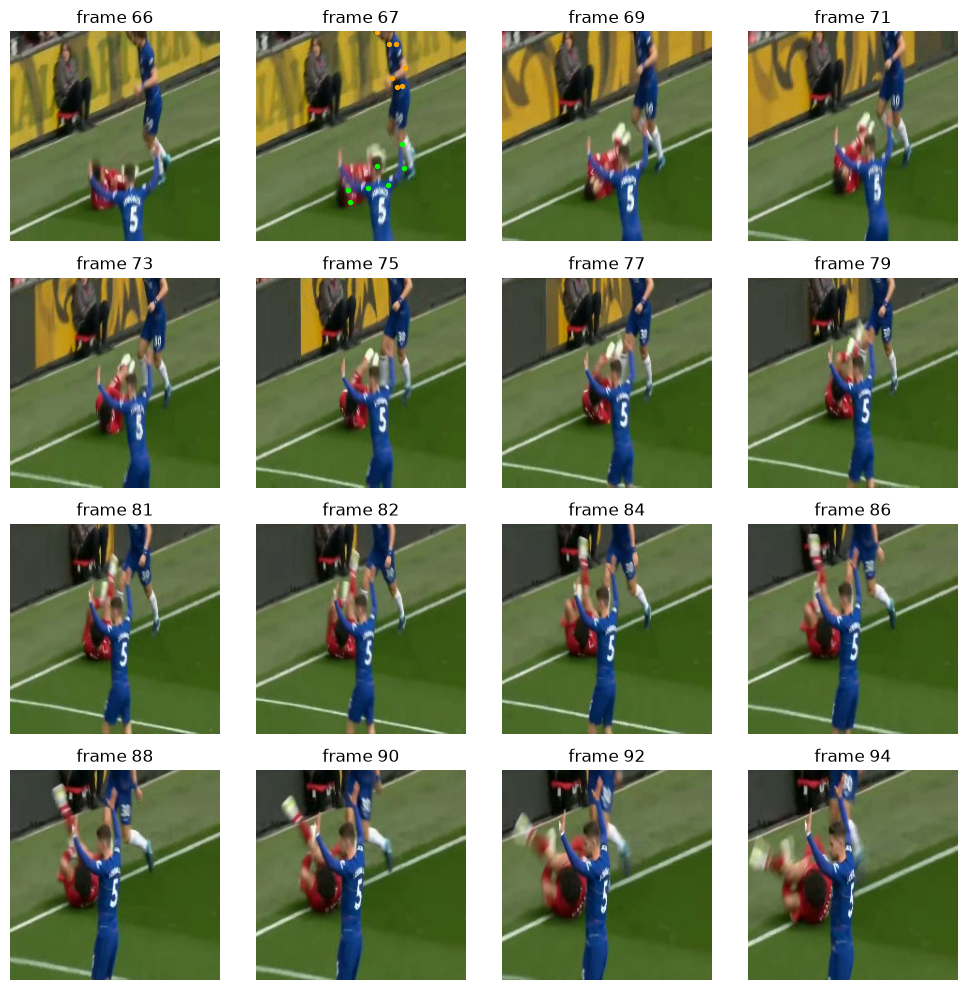

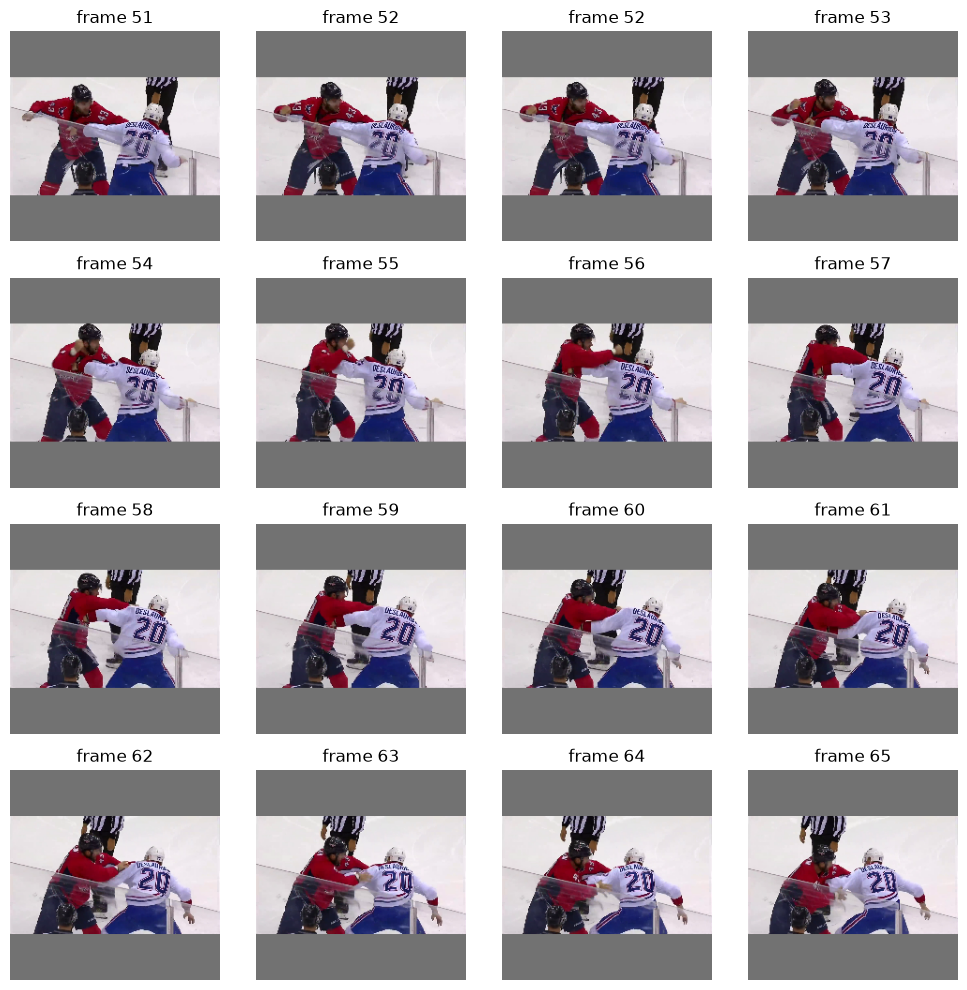

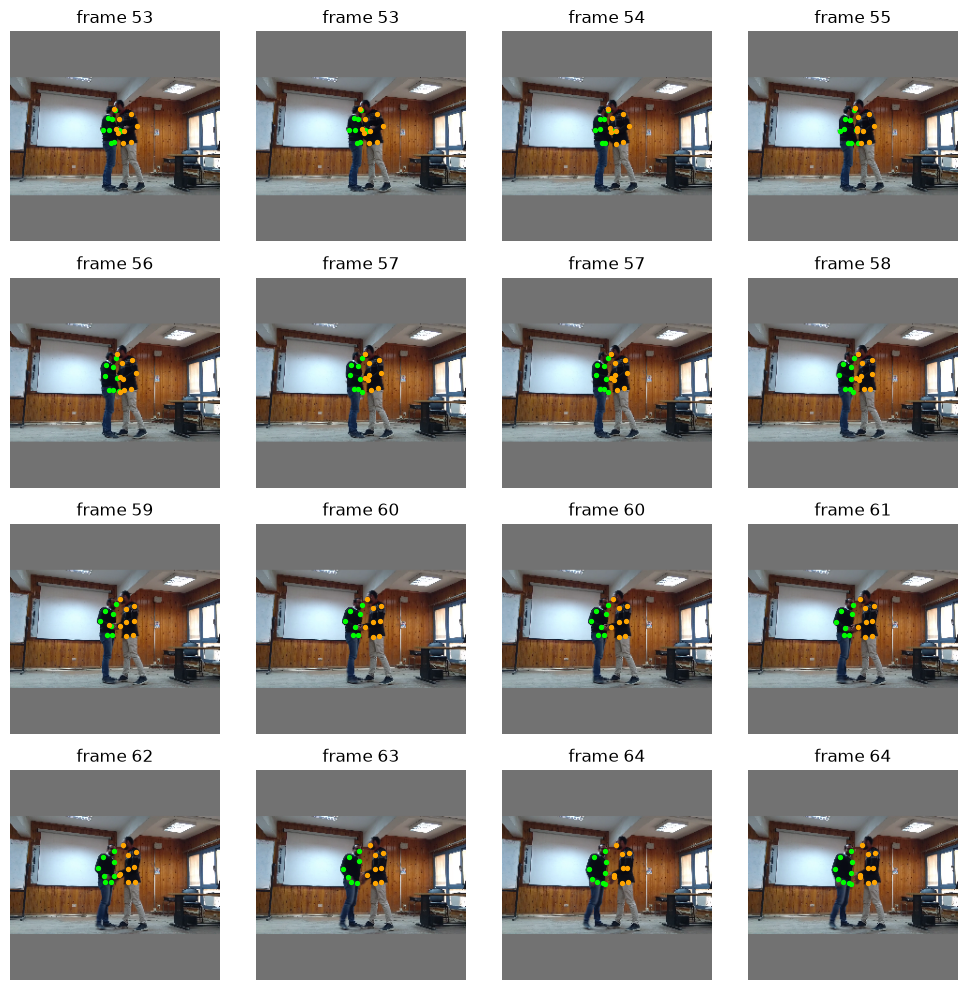

In [6]:
import matplotlib.pyplot as plt
def preview(row):
    start=float(np.clip(row.t-row.length/2,row.a,row.b-row.length))
    x,g,ids=read_window(row.path,start,row.length,row.digest)
    fig,axes=plt.subplots(4,4,figsize=(10,10))
    cap=cv2.VideoCapture(row.path)
    w,h=cap.get(cv2.CAP_PROP_FRAME_WIDTH),cap.get(cv2.CAP_PROP_FRAME_HEIGHT);cap.release()
    wh=np.maximum(1,np.round(np.array([w,h])*224/max(w,h)))
    for ax,img,people,i in zip(axes.flat,x,g.reshape(16,2,len(JOINTS),3).numpy(),ids):
        ax.imshow((img.permute(1,2,0).numpy()*STD+MEAN).clip(0,1))
        for person,color in zip(people,['lime','orange']):
            pts=person[person[:,2]>0,:2]*wh+(224-wh)//2
            ax.scatter(pts[:,0],pts[:,1],c=color,s=8)
        ax.set_title(f'frame {i}');ax.axis('off')
    plt.tight_layout();plt.show()
for scenario in ['arm_overlap','fast_strike','friendly_touch','occluded']:
    examples=samples[(samples.scenario==scenario)&(samples.split=='train')]
    if len(examples): preview(examples.iloc[0])

### Huấn luyện hai đầu ra

Đầu hành động dùng đặc trưng VideoMAE của cả đoạn. Đầu tiếp xúc kết hợp đặc trưng ảnh với chuỗi khớp của cặp người. Đánh giá cả hai thứ tự của cặp rồi lấy trung bình để thứ tự A/B không làm đổi điểm. RLVS vẫn đóng góp vào loss hành động khi thiếu nhãn tiếp xúc. Chọn best.pt theo F1 hành động và macro-F1 tiếp xúc trên validation có đủ lớp. Trường hợp thiếu nhãn sẽ được ghi rõ trong kết quả.

Đặt OUT mới cho mỗi lần train. Đặt OLD_BEST nếu muốn khởi tạo từ state_dict phân loại hai lớp của V1.

In [7]:
class ContactVideoMAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.video=VideoMAEForVideoClassification.from_pretrained(BASE,num_labels=2,ignore_mismatched_sizes=True)
        self.pose=nn.GRU(PAIR_DIM,64,batch_first=True,bidirectional=True)
        self.contact=nn.Sequential(nn.Linear(self.video.config.hidden_size+128,128),nn.GELU(),nn.Dropout(.2),nn.Linear(128,3))
        self.action_pose=nn.Linear(128,2,bias=False)
        nn.init.zeros_(self.action_pose.weight)
    def forward(self,x,g):
        tokens=self.video.videomae(pixel_values=x).last_hidden_state
        pooled=self.video.fc_norm(tokens.mean(1)) if self.video.fc_norm is not None else tokens[:,0]
        action=self.video.classifier(pooled)
        swapped=g.reshape(len(g),16,2,-1).flip(2).reshape_as(g)
        _,h=self.pose(torch.cat([g,swapped],0))
        encoded=h.transpose(0,1).reshape(2*len(g),128)
        correction=self.action_pose(encoded.reshape(2,len(g),128).mean(0))
        action=action+correction*pose_quality(g).unsqueeze(1)
        logits=self.contact(torch.cat([pooled.repeat(2,1),encoded],1))
        return action,logits.reshape(2,len(g),3).mean(0)

def masked_loss(logits,target):
    valid=target>=0
    if valid.any(): return F.cross_entropy(logits[valid],target[valid])
    return logits.sum()*0

def pose_quality(g):
    seen=g.abs().sum(-1)>0
    return (seen.float().mean(1)>=.5)&seen[:,5:11].any(1)

@torch.inference_mode()
def predictions(net,split):
    net.eval()
    rows=[]
    for x,g,action,contact in loader(split):
        with torch.autocast('cuda',dtype=torch.float16):
            a,c=net(x.to(device),g.to(device))
        for av,cv,y,z,q in zip(a.float().softmax(-1)[:,1].tolist(),c.float().softmax(-1).tolist(),action.tolist(),contact.tolist(),pose_quality(g).tolist()):
            rows.append([av,*cv,y,z,q])
    df=samples[samples.split==split].reset_index(drop=True).copy()
    df[['p_action','p_no_touch','p_touch','p_unclear','y','z','pose_ok']]=pd.DataFrame(rows)
    return df

def head_scores(df):
    actions=df[df.y>=0]
    af=float(f1_score(actions.y,actions.p_action>=.5,zero_division=0))
    labeled=df[df.z>=0]
    cf=None
    if set(labeled.z)=={0,1,2}:
        pred=labeled[['p_no_touch','p_touch','p_unclear']].to_numpy().argmax(1)
        cf=float(f1_score(labeled.z,pred,labels=[0,1,2],average='macro',zero_division=0))
    return af,cf

def atomic_save(obj,path):
    tmp=path.with_suffix('.tmp')
    torch.save(obj,tmp);os.replace(tmp,path)

In [8]:
if device.type!='cuda': raise RuntimeError('Chọn kernel có PyTorch CUDA trong VS Code.')
if EPOCHS<1 or ACCUM<1: raise ValueError('EPOCHS và ACCUM phải dương')
OUT.mkdir(exist_ok=True,parents=True)
if (OUT/'best.pt').exists(): raise FileExistsError('Chọn OUT mới để giữ best.pt hiện có')
samples.to_csv(OUT/'manifest.csv',index=False)
net=ContactVideoMAE().to(device)
net.video.videomae.requires_grad_(False)
net.video.videomae.encoder.layer[-1].requires_grad_(True)
if OLD_BEST:
    net.video.load_state_dict(torch.load(OLD_BEST,map_location='cpu',weights_only=True))
# Check actual pair visibility on the labeled windows using the Colab runtime.
# This also fills the pose cache used by the training loader.
event_windows=samples[samples.scenario!='base'].reset_index(drop=True)
audit=[]
net.eval()
with torch.inference_mode():
    for j in tqdm(range(len(event_windows)),desc='Kiểm tra pose trước train'):
        row=event_windows.iloc[j]
        x,g,y,z=Clips(event_windows)[j]
        audit.append(dict(path=row.path,split=row.split,scenario=row.scenario,
                          length=row.length,target=z,pose_ok=pose_quality(g[None]).item()))
        if j==0:
            with torch.autocast('cuda',dtype=torch.float16):
                before,contact_logits=net(x[None].to(device),g[None].to(device))
            assert before.shape==(1,2) and contact_logits.shape==(1,3)
            assert torch.isfinite(before).all() and torch.isfinite(contact_logits).all()
pose_report=pd.DataFrame(audit)
if len(pose_report):
    pose_report.to_csv(OUT/'pose_preflight.csv',index=False)
    display(pose_report.groupby(['split','scenario']).pose_ok.agg(['sum','count']))

train=loader('train',True)
body=[p for p in net.video.videomae.parameters() if p.requires_grad]
body_ids={id(p) for p in body}
heads=[p for p in net.parameters() if p.requires_grad and id(p) not in body_ids]
opt=torch.optim.AdamW([{'params':body,'lr':2e-5},{'params':heads,'lr':2e-4}],weight_decay=.05,foreach=False)
steps=math.ceil(len(train)/ACCUM)*EPOCHS
warm=max(1,round(.1*steps))
def rate(i):
    if i<warm: return (i+1)/warm
    return .5*(1+math.cos(math.pi*(i-warm)/max(1,steps-warm)))
schedule=torch.optim.lr_scheduler.LambdaLR(opt,rate)
scaler=torch.amp.GradScaler('cuda')
best=-1.; history=[]
seen_contact=set()
for epoch in range(EPOCHS):
    net.train();opt.zero_grad(set_to_none=True)
    for i,(x,g,y,z) in enumerate(tqdm(train,desc=f'Epoch {epoch+1}')):
        seen_contact.update(z[z>=0].tolist())
        x,g,y,z=[v.to(device) for v in (x,g,y,z)]
        first=i//ACCUM*ACCUM
        end=min(first+ACCUM,len(train))
        count=min(end*BATCH,len(train.sampler))-first*BATCH
        with torch.autocast('cuda',dtype=torch.float16):
            a,c=net(x,g)
            loss=masked_loss(a,y)+masked_loss(c,z)
        scaler.scale(loss*len(x)/count).backward()
        if not torch.isfinite(loss.detach()): raise FloatingPointError(f'Loss không hữu hạn ở epoch {epoch+1}, batch {i+1}')
        if i+1==end:
            scaler.unscale_(opt);torch.nn.utils.clip_grad_norm_(net.parameters(),1.)
            old=scaler.get_scale();scaler.step(opt);scaler.update()
            if scaler.get_scale()>=old:
                schedule.step()
                if schedule.last_epoch==1:
                    print('CUDA: bước optimizer đầu tiên của V2 thành công. Loss:',loss.item(),flush=True)
            opt.zero_grad(set_to_none=True)
    val=predictions(net,'val')
    af,cf=head_scores(val)
    selection=(af+cf)/2 if cf is not None else af
    history.append(dict(epoch=epoch+1,action_f1=af,contact_macro_f1=cf,selection=selection))
    if selection>best:
        best=selection
        atomic_save({'format':'v2_contact_1','model':net.state_dict(),'epoch':epoch+1,'seen_contact':sorted(seen_contact),'base':BASE,'contact_labels':CONTACT},OUT/'best.pt')
    (OUT/'history.json').write_text(json.dumps(history,indent=2))
    print(history[-1])

Some weights of VideoMAEForVideoClassification were not initialized from the model checkpoint at d:\TaiLieu\2026-2027\ATTT\train_v2\cache\hf and are newly initialized because the shapes did not match:
- classifier.bias: found shape torch.Size([400]) in the checkpoint and torch.Size([2]) in the model instantiated
- classifier.weight: found shape torch.Size([400, 768]) in the checkpoint and torch.Size([2, 768]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Kiểm tra pose trước train: 100%|██████████| 42/42 [00:13<00:00,  3.22it/s]


sum  count
split scenario                  
test  arm_overlap       2      2
      body_overlap      0      2
      fast_strike       0      3
      grappling         1      3
      hand_gesture      2      2
train arm_overlap       0      2
      fast_strike       3      9
      friendly_touch    2      4
      hand_gesture      0      2
val   arm_overlap       0      2
      fast_strike       0      3
      friendly_touch    0      3
      grappling         0      3
      hand_gesture      0      2

Epoch 1:   1%|          | 15/1465 [00:05<11:56,  2.02it/s]

CUDA: bước optimizer đầu tiên của V2 thành công. Loss: 0.97607421875


Epoch 1: 100%|██████████| 1465/1465 [09:54<00:00,  2.46it/s]


{'epoch': 1, 'action_f1': 0.9702970297029703, 'contact_macro_f1': 0.6262626262626262, 'selection': 0.7982798279827983}


... (4 outputs left out)

Epoch 4: 100%|██████████| 1465/1465 [08:46<00:00,  2.78it/s]


{'epoch': 4, 'action_f1': 0.9900332225913622, 'contact_macro_f1': 0.707936507936508, 'selection': 0.8489848652639351}


Epoch 5: 100%|██████████| 1465/1465 [09:02<00:00,  2.70it/s]


{'epoch': 5, 'action_f1': 0.9900332225913622, 'contact_macro_f1': 0.707936507936508, 'selection': 0.8489848652639351}


### Chọn ngưỡng và đo lỗi

Dùng validation để chọn ngưỡng nghi vấn theo F1 hành động. Với cửa sổ hành động vượt ngưỡng, nhánh tiếp xúc có thể nâng mức cảnh báo khi cặp người đủ rõ và điểm chạm đủ cao. Đo số báo nhầm **gồm cả nghi ngờ**, số cảnh báo đánh nhau, số bỏ sót và số nguồn. Kết quả theo cửa sổ gắn nhãn. Khi thiếu dữ liệu tiếp xúc để hiệu chỉnh, demo chỉ xuất mức bình thường hoặc nghi ngờ.

In [9]:
def decide(pa,pc,quality,policy):
    if pa<policy['action_threshold']: return 'normal'
    if (policy['contact_ready'] and quality and int(np.argmax(pc))==1
        and pc[1]>=policy['touch_threshold']): return 'fight'
    return 'suspected'

def calibrate(val,seen):
    grid=np.linspace(.05,.95,91)
    act=val[val.y>=0]
    at=max(grid,key=lambda t:(f1_score(act.y,act.p_action>=t,zero_division=0),-abs(t-.5)))
    observable=val[(val.z>=0)&(val.pose_ok==True)]
    ready=set(seen)=={0,1,2} and set(observable.z)=={0,1,2}
    ct=1.
    if ready:
        probs=observable[['p_no_touch','p_touch','p_unclear']].to_numpy()
        ct=max(grid,key=lambda t:f1_score(observable.z==1,(probs.argmax(1)==1)&(probs[:,1]>=t),zero_division=0))
    return dict(action_threshold=float(at),touch_threshold=float(ct),contact_ready=ready)

def report(df,policy,name):
    probs=df[['p_no_touch','p_touch','p_unclear']].to_numpy()
    df['decision']=[decide(a,c,q,policy) for a,c,q in zip(df.p_action,probs,df.pose_ok)]
    df.to_csv(OUT/f'{name}_predictions.csv',index=False)
    labeled=df[df.z>=0]
    if len(labeled):
        pred=labeled[['p_no_touch','p_touch','p_unclear']].to_numpy().argmax(1)
        print('Contact rows=true, cols=pred',CONTACT,confusion_matrix(labeled.z,pred,labels=[0,1,2]),sep='\n')
    table=[]
    for scenario,part in df.groupby('scenario'):
        neg=part[part.y==0];pos=part[part.y==1]
        table.append(dict(scenario=scenario,sources=part.source.nunique(),windows=len(part),
            normal=len(neg),strikes=len(pos),false_logs=int((neg.decision!='normal').sum()),
            false_fight=int((neg.decision=='fight').sum()),missed=int((pos.decision=='normal').sum()),
            review_strikes=int((pos.decision=='suspected').sum()),fight_strikes=int((pos.decision=='fight').sum())))
    result=pd.DataFrame(table)
    result['false_log_rate']=result.false_logs/result.normal.replace(0,np.nan)
    result['strike_recall_including_review']=1-result.missed/result.strikes.replace(0,np.nan)
    result.to_csv(OUT/f'{name}_summary.csv',index=False);display(result)

ck=torch.load(OUT/'best.pt',map_location='cpu',weights_only=True)
net.load_state_dict(ck['model'])
val=predictions(net,'val')
policy=calibrate(val,ck['seen_contact'])
(OUT/'policy.json').write_text(json.dumps(policy,indent=2))
print(policy)
report(val,policy,'val')
report(predictions(net,'test'),policy,'test')

{'action_threshold': 0.49999999999999994, 'touch_threshold': 1.0, 'contact_ready': False}
Contact rows=true, cols=pred
['no_touch', 'touch', 'unclear']
[[3 1 0]
 [0 3 3]
 [0 0 3]]


,scenario,sources,windows,normal,strikes,false_logs,false_fight,missed,review_strikes,fight_strikes,false_log_rate,strike_recall_including_review
0,arm_overlap,1,2,2,0,0,0,0,0,0,0.000000,NaN
1,base,265,310,166,144,2,0,1,143,0,0.012048,0.993056
2,fast_strike,1,3,0,3,0,0,0,3,0,NaN,1.000000
3,friendly_touch,1,3,3,0,0,0,0,0,0,0.000000,NaN
4,grappling,1,3,0,3,0,0,0,3,0,NaN,1.000000
5,hand_gesture,1,2,2,0,0,0,0,0,0,0.000000,NaN


Contact rows=true, cols=pred
['no_touch', 'touch', 'unclear']
[[3 1 0]
 [0 0 3]
 [2 0 3]]


,scenario,sources,windows,normal,strikes,false_logs,false_fight,missed,review_strikes,fight_strikes,false_log_rate,strike_recall_including_review
0,arm_overlap,1,2,2,0,0,0,0,0,0,0.000000,NaN
1,base,272,287,143,144,2,0,2,142,0,0.013986,0.986111
2,body_overlap,1,2,2,0,0,0,0,0,0,0.000000,NaN
3,fast_strike,1,3,0,3,0,0,0,3,0,NaN,1.000000
4,grappling,1,3,0,3,0,0,0,3,0,NaN,1.000000
5,hand_gesture,1,2,2,0,0,0,0,0,0,0.000000,NaN


### Thử clip mới hoặc các video KO

Điền đường dẫn vào KO_FILES. Dùng cùng checkpoint, phép chuẩn hóa, pose và ngưỡng. Các cửa sổ chồng lấn có thể tạo nhiều dòng cho cùng một sự kiện. Cột start_s/end_s giúp mở lại đúng đoạn. Một cửa sổ có thể phát cảnh báo cho cú đánh đơn. Báo cáo validation/test ở trên dùng cửa sổ có nhãn, còn phép thử này quét toàn clip.

In [10]:
@torch.inference_mode()
def scan_video(path,step_s=.2):
    net.eval()
    path=str(Path(path).resolve())
    n,fps=info(path);duration=n/fps;digest=file_hash(path)
    rows=[]
    for length in sorted({min(w,duration) for w in SCALES}):
        last=duration-length
        starts=np.unique(np.append(np.arange(0,last,step_s),last))
        for start in starts:
            x,g,_=read_window(path,start,length,digest)
            with torch.autocast('cuda',dtype=torch.float16):
                a,c=net(x[None].to(device),g[None].to(device))
            pa=a.softmax(-1)[0,1].item();pc=c.softmax(-1)[0].cpu().numpy()
            ok=pose_quality(g[None]).item()
            rows.append(dict(path=path,start_s=start,end_s=start+length,p_action=pa,p_touch=pc[1],
                             p_unclear=pc[2],pose_ok=ok,decision=decide(pa,pc,ok,policy)))
    return pd.DataFrame(rows)
ko_dirs=[DATA_ROOT]
KO_FILES=[next(d/name for d in ko_dirs if (d/name).is_file())
          for name in ['KO_1s.mp4','KO3_2s.mp4','KO4_dai.mp4'] if any((d/name).is_file() for d in ko_dirs)]
if KO_FILES:
    ko=pd.concat([scan_video(p) for p in KO_FILES],ignore_index=True)
    ko.to_csv(OUT/'ko_windows.csv',index=False);display(ko)
print('Checkpoint:',OUT/'best.pt')

d:\TaiLieu\2026-2027\ATTT\.venv\Lib\site-packages\pandas\io\formats\format.py:1486: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,path,start_s,end_s,p_action,p_touch,p_unclear,pose_ok,decision
0,D:\TaiLieu\2026-2027\ATTT\KO_1s.mp4,0.0,0.5,0.913574,0.305420,0.530273,False,suspected
1,D:\TaiLieu\2026-2027\ATTT\KO_1s.mp4,0.2,0.7,0.895020,0.343994,0.468994,False,suspected
2,D:\TaiLieu\2026-2027\ATTT\KO_1s.mp4,0.4,0.9,0.895020,0.430420,0.405762,False,suspected
3,D:\TaiLieu\2026-2027\ATTT\KO_1s.mp4,0.5,1.0,0.876953,0.413330,0.399658,False,suspected
4,D:\TaiLieu\2026-2027\ATTT\KO_1s.mp4,0.0,1.0,0.857422,0.367676,0.436035,False,suspected
5,D:\TaiLieu\2026-2027\ATTT\KO3_2s.mp4,0.0,0.5,0.945312,0.230469,0.678711,False,suspected
6,D:\TaiLieu\2026-2027\ATTT\KO3_2s.mp4,0.2,0.7,0.940430,0.194092,0.727051,False,suspected
7,D:\TaiLieu\2026-2027\ATTT\KO3_2s.mp4,0.4,0.9,0.912109,0.258545,0.650879,False,suspected
8,D:\TaiLieu\2026-2027\ATTT\KO3_2s.mp4,0.6,1.1,0.901855,0.330078,0.576172,False,suspected
9,D:\TaiLieu\2026-2027\ATTT\KO3_2s.mp4,0.8,1.3,0.781738,0.403076,0.468262,False,suspected


Checkpoint: d:\TaiLieu\2026-2027\ATTT\train_v2\runs\local_gpu_01\best.pt
